# LSTM Networks for Structured and Unstructured Data

**Lab experiment:** Implement LSTM and Bidirectional LSTM models to learn sequential patterns from structured time-series data and unstructured audio data.

## Objectives

1. Build LSTM and Bidirectional LSTM models for time-series forecasting.
2. Apply MinMax scaling and create fixed-length sliding windows from structured data.
3. Convert audio waveforms into sequential MFCC features using Librosa.
4. Train LSTM and Bidirectional LSTM models for spoken-digit classification.
5. Compare the models using suitable evaluation metrics and plots.

**Google Colab setup:** Runtime → Change runtime type → GPU (optional). The notebook also runs on CPU, although training may take longer.

The notebook has two independent tracks. Run the cells from top to bottom.

## Track 1 — Structured data: weather time-series forecasting

We use the Jena Climate dataset. The original measurements are recorded every 10 minutes. To keep this experiment manageable, we sample one observation per hour.

**Task:** Use the previous 24 hours of weather measurements to predict the air temperature one hour ahead.

We compare:
- LSTM
- Bidirectional LSTM

The data is split chronologically into training, validation, and test sets. MinMax scaling is fitted only on the training portion to avoid data leakage.

In [1]:
# STEP 1: IMPORT LIBRARIES

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow version: 2.21.0
GPU available: True


In [2]:
# STEP 2: DOWNLOAD THE JENA CLIMATE DATASET

zip_path = tf.keras.utils.get_file(
    origin="https://storage.googleapis.com/tensorflow/tf-keras-datasets/"
           "jena_climate_2009_2016.csv.zip",
    fname="jena_climate_2009_2016.csv.zip",
    extract=True
)

csv_path = os.path.splitext(zip_path)[0]

if os.path.isdir(csv_path):
    csv_path = os.path.join(csv_path, "jena_climate_2009_2016.csv")

df = pd.read_csv(csv_path)

print("Dataset downloaded successfully.")
print("Original shape:", df.shape)
display(df.head())

13568290/13568290 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset downloaded successfully.
Original shape: (420551, 15)


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


In [3]:
# STEP 3: PREPROCESS THE WEATHER DATA

# Keep one reading per hour (the source data is recorded every 10 minutes).
df = df.iloc[5::6].copy()

# Parse the timestamp and sort chronologically.
df["Date Time"] = pd.to_datetime(
    df["Date Time"],
    format="%d.%m.%Y %H:%M:%S"
)

df = df.sort_values("Date Time").reset_index(drop=True)

# Use all numeric weather variables as model inputs.
feature_columns = df.select_dtypes(include=np.number).columns.tolist()
target_column = "T (degC)"

if target_column not in feature_columns:
    raise ValueError(f"Target column {target_column!r} was not found.")

# Remove any rows containing missing numeric values.
df = df.dropna(subset=feature_columns).reset_index(drop=True)

print("Processed shape:", df.shape)
print("Number of input features:", len(feature_columns))
print("Features:", feature_columns)

Processed shape: (70091, 15)
Number of input features: 14
Features: ['p (mbar)', 'T (degC)', 'Tpot (K)', 'Tdew (degC)', 'rh (%)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'sh (g/kg)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'max. wv (m/s)', 'wd (deg)']


In [4]:
# STEP 4: CHRONOLOGICAL SPLIT AND MINMAX SCALING

values = df[feature_columns].to_numpy(dtype=np.float32)
target_values = df[[target_column]].to_numpy(dtype=np.float32)

n_rows = len(df)
train_end = int(0.70 * n_rows)
val_end = int(0.85 * n_rows)

X_train_raw = values[:train_end]
X_val_raw = values[train_end:val_end]
X_test_raw = values[val_end:]

y_train_raw = target_values[:train_end]
y_val_raw = target_values[train_end:val_end]
y_test_raw = target_values[val_end:]

# Fit scalers using the training data only.
feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

X_train_scaled = feature_scaler.fit_transform(X_train_raw)
X_val_scaled = feature_scaler.transform(X_val_raw)
X_test_scaled = feature_scaler.transform(X_test_raw)

y_train_scaled = target_scaler.fit_transform(y_train_raw)
y_val_scaled = target_scaler.transform(y_val_raw)
y_test_scaled = target_scaler.transform(y_test_raw)

print("Training rows:", len(X_train_scaled))
print("Validation rows:", len(X_val_scaled))
print("Testing rows:", len(X_test_scaled))

Training rows: 49063
Validation rows: 10514
Testing rows: 10514


In [5]:
# STEP 5: CREATE SLIDING-WINDOW SEQUENCES

LOOKBACK = 24  # Previous 24 hourly observations.

def create_windows(features, targets, lookback):
    X, y = [], []

    for i in range(len(features) - lookback):
        X.append(features[i:i + lookback])
        y.append(targets[i + lookback])

    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)


X_train, y_train = create_windows(X_train_scaled, y_train_scaled, LOOKBACK)
X_val, y_val = create_windows(X_val_scaled, y_val_scaled, LOOKBACK)
X_test, y_test = create_windows(X_test_scaled, y_test_scaled, LOOKBACK)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "y_test: ", y_test.shape)

# Each input has shape: (24 time steps, number of weather features).

X_train: (49039, 24, 14) y_train: (49039, 1)
X_val:   (10490, 24, 14) y_val:   (10490, 1)
X_test:  (10490, 24, 14) y_test:  (10490, 1)


In [6]:
# STEP 6: BUILD THE LSTM MODEL

def build_lstm_model(input_shape):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        tf.keras.layers.LSTM(32),
        tf.keras.layers.Dense(1)
    ])

    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )
    return model


lstm_model = build_lstm_model(
    input_shape=(LOOKBACK, len(feature_columns))
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         6,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,049 (23.63 KB)

 Trainable params: 6,049 (23.63 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# STEP 7: BUILD THE BIDIRECTIONAL LSTM MODEL

def build_bilstm_model(input_shape):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(32)
        ),
        tf.keras.layers.Dense(1)
    ])

    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )
    return model


bilstm_model = build_bilstm_model(
    input_shape=(LOOKBACK, len(feature_columns))
)

bilstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 64)             │        12,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,097 (47.25 KB)

 Trainable params: 12,097 (47.25 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# STEP 8: TRAIN BOTH STRUCTURED-DATA MODELS

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

EPOCHS = 10
BATCH_SIZE = 64

print("Training LSTM...")
history_lstm = lstm_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1
)

print("\nTraining Bidirectional LSTM...")
history_bilstm = bilstm_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Training LSTM...
Epoch 1/10
767/767 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - loss: 0.0031 - mae: 0.0278 - val_loss: 5.6882e-04 - val_mae: 0.0129
Epoch 2/10
767/767 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 2.6027e-04 - mae: 0.0118 - val_loss: 6.8659e-04 - val_mae: 0.0112
Epoch 3/10
767/767 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 2.1970e-04 - mae: 0.0108 - val_loss: 7.9773e-04 - val_mae: 0.0113
Epoch 4/10
767/767 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 1.9931e-04 - mae: 0.0102 - val_loss: 7.8271e-04 - val_mae: 0.0105

Training Bidirectional LSTM...
Epoch 1/10
767/767 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - loss: 0.0035 - mae: 0.0327 - val_loss: 8.0866e-04 - val_mae: 0.0190
Epoch 2/10
767/767 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - loss: 4.1608e-04 - mae: 0.0152 - val_loss: 4.9909e-04 - val_mae: 0.0135
Epoch 3/10
767/767 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - loss: 2.6840e-04 - mae: 0.0120 - val_loss: 4.2423e-04 - val_mae: 0.0121
Epoch 4/10
767/767 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - loss: 2.1930e-04

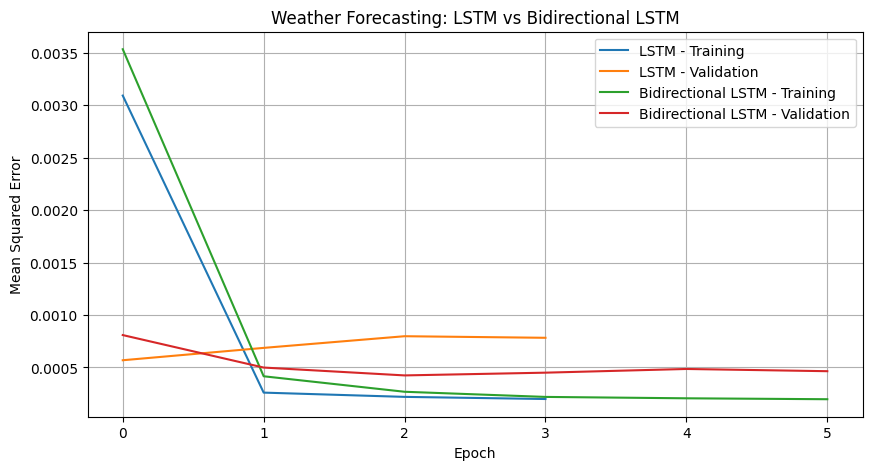

In [9]:
# STEP 9: PLOT TRAINING AND VALIDATION LOSS

plt.figure(figsize=(10, 5))

plt.plot(history_lstm.history["loss"], label="LSTM - Training")
plt.plot(history_lstm.history["val_loss"], label="LSTM - Validation")
plt.plot(history_bilstm.history["loss"], label="Bidirectional LSTM - Training")
plt.plot(history_bilstm.history["val_loss"], label="Bidirectional LSTM - Validation")

plt.title("Weather Forecasting: LSTM vs Bidirectional LSTM")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
# STEP 10: EVALUATE WEATHER-TEMPERATURE PREDICTIONS

def regression_results(model, X_test, y_test_scaled, scaler):
    pred_scaled = model.predict(X_test, verbose=0)

    actual = scaler.inverse_transform(y_test_scaled.reshape(-1, 1)).ravel()
    predicted = scaler.inverse_transform(pred_scaled).ravel()

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    return actual, predicted, mae, rmse


actual_temp, lstm_temp, lstm_mae, lstm_rmse = regression_results(
    lstm_model, X_test, y_test, target_scaler
)

_, bilstm_temp, bilstm_mae, bilstm_rmse = regression_results(
    bilstm_model, X_test, y_test, target_scaler
)

structured_results = pd.DataFrame({
    "Model": ["LSTM", "Bidirectional LSTM"],
    "MAE (°C)": [lstm_mae, bilstm_mae],
    "RMSE (°C)": [lstm_rmse, bilstm_rmse]
})

display(structured_results)

,Model,MAE (°C),RMSE (°C)
0,LSTM,0.711882,0.960275
1,Bidirectional LSTM,0.653059,0.878773


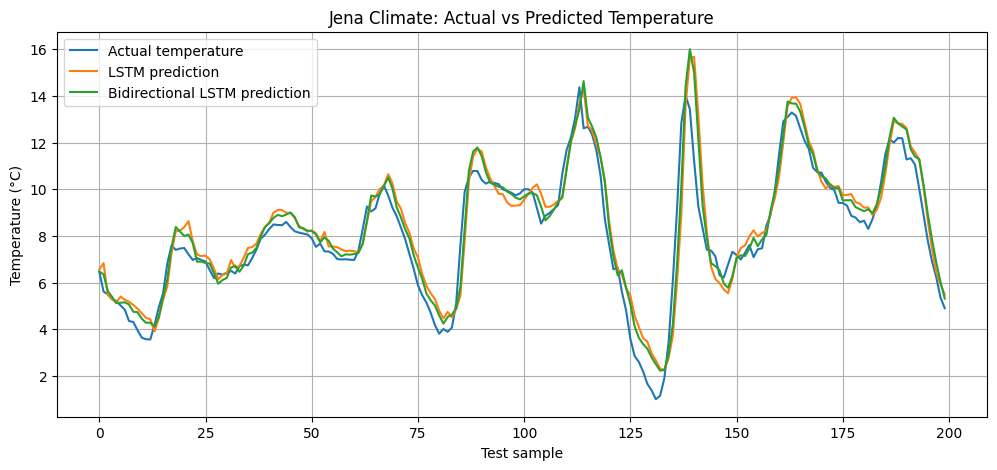

In [11]:
# STEP 11: PLOT ACTUAL VS PREDICTED TEMPERATURE

n_plot = min(200, len(actual_temp))

plt.figure(figsize=(12, 5))
plt.plot(actual_temp[:n_plot], label="Actual temperature")
plt.plot(lstm_temp[:n_plot], label="LSTM prediction")
plt.plot(bilstm_temp[:n_plot], label="Bidirectional LSTM prediction")

plt.title("Jena Climate: Actual vs Predicted Temperature")
plt.xlabel("Test sample")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.show()

## Track 2 — Unstructured data: spoken-digit audio classification

We use the **Free Spoken Digit Dataset** through TensorFlow Datasets (`spoken_digit`). It contains short recordings of spoken digits from 0 to 9.

The audio waveform is a one-dimensional signal, not a conventional table. Librosa converts each waveform into a sequence of Mel-Frequency Cepstral Coefficients (MFCCs). The LSTM then learns patterns across the time frames.

We compare:
- LSTM
- Bidirectional LSTM

The dataset provides filenames containing recording numbers. We use recordings numbered 0–4 for testing and split the remaining recordings into training and validation sets.

In [12]:
# STEP 12: INSTALL AND IMPORT AUDIO-PROCESSING LIBRARIES

!pip -q install librosa tensorflow-datasets

import librosa
import tensorflow_datasets as tfds

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from IPython.display import Audio, display

print("Librosa version:", librosa.__version__)

Librosa version: 0.11.0


In [14]:
# STEP 13: DOWNLOAD THE SPOKEN DIGIT DATASET

!pip -q install importlib_resources

import tensorflow_datasets as tfds

audio_ds, audio_info = tfds.load(
    "spoken_digit",
    split="train",
    as_supervised=False,
    with_info=True
)

print(audio_info)
print("Class names:", audio_info.features["label"].names)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

/usr/local/lib/python3.13/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
  m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
  m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(flt)p?( \(default\))?$', token):
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(dbl)p?( \(default\))?$', token):


Shuffling /root/tensorflow_datasets/spoken_digit/incomplete.F1CBFN_1.0.9/spoken_digit-train.tfrecord-[0-9][0-9…

Dataset spoken_digit downloaded and prepared to /root/tensorflow_datasets/spoken_digit/1.0.9. Subsequent calls will reuse this data.
tfds.core.DatasetInfo(
    name='spoken_digit',
    full_name='spoken_digit/1.0.9',
    description="""
    A free audio dataset of spoken digits. Think MNIST for audio.
    
    A simple audio/speech dataset consisting of recordings of spoken digits in wav
    files at 8kHz.
    The recordings are trimmed so that they have near minimal silence at the
    beginnings and ends.
    
    5 speakers\
    2,500 recordings (50 of each digit per speaker)\
    English pronunciations
    
    Files are named in the following format: {digitLabel}_{speakerName}_{index}.wav
    """,
    homepage='https://github.com/Jakobovski/free-spoken-digit-dataset',
    data_dir='/root/tensorflow_datasets/spoken_digit/1.0.9',
    file_format=tfrecord,
    download_size=11.42 MiB,
    dataset_size=45.68 MiB,
    features=FeaturesDict({
        'audio': Audio(shape=(None,), dtype=i

In [15]:
# STEP 14: CONVERT EACH AUDIO WAVEFORM INTO MFCC SEQUENCES

SAMPLE_RATE = 8000   # Dataset audio is sampled at 8 kHz.
N_MFCC = 13
MAX_FRAMES = 64      # Fixed sequence length for the LSTM.

def waveform_to_mfcc(waveform):
    waveform = np.asarray(waveform, dtype=np.float32)

    # TFDS stores the decoded waveform as integer PCM values.
    if np.max(np.abs(waveform)) > 1.0:
        waveform = waveform / 32768.0

    mfcc = librosa.feature.mfcc(
        y=waveform,
        sr=SAMPLE_RATE,
        n_mfcc=N_MFCC,
        n_fft=256,
        hop_length=128
    )

    # Shape becomes (time frames, MFCC coefficients).
    mfcc = mfcc.T

    # Pad or truncate so every audio sample has the same sequence length.
    if mfcc.shape[0] < MAX_FRAMES:
        pad_rows = MAX_FRAMES - mfcc.shape[0]
        mfcc = np.pad(
            mfcc,
            ((0, pad_rows), (0, 0)),
            mode="constant"
        )
    else:
        mfcc = mfcc[:MAX_FRAMES, :]

    return mfcc.astype(np.float32)


audio_sequences = []
audio_labels = []
audio_filenames = []

for item in tfds.as_numpy(audio_ds):
    waveform = item["audio"]
    label = int(item["label"])

    filename = item["audio/filename"]
    if isinstance(filename, bytes):
        filename = filename.decode("utf-8")

    filename = os.path.basename(filename)

    mfcc_sequence = waveform_to_mfcc(waveform)

    audio_sequences.append(mfcc_sequence)
    audio_labels.append(label)
    audio_filenames.append(filename)

X_audio = np.asarray(audio_sequences, dtype=np.float32)
y_audio = np.asarray(audio_labels, dtype=np.int64)

print("Audio sequence array:", X_audio.shape)
print("Label array:", y_audio.shape)
print("Example filenames:", audio_filenames[:5])

Audio sequence array: (2500, 64, 13)
Label array: (2500,)
Example filenames: ['2_nicolas_23.wav', '1_nicolas_0.wav', '9_theo_30.wav', '9_yweweler_4.wav', '7_nicolas_22.wav']


In [16]:
# STEP 15: CREATE TRAIN, VALIDATION AND TEST SETS

# The FSDD naming convention ends with the recording number.
# Recordings 0-4 are used as the test set; 5-49 are used for train/validation.

recording_numbers = []

for filename in audio_filenames:
    stem = os.path.splitext(filename)[0]
    recording_number = int(stem.split("_")[-1])
    recording_numbers.append(recording_number)

recording_numbers = np.asarray(recording_numbers)

test_indices = np.where(recording_numbers <= 4)[0]
trainval_indices = np.where(recording_numbers > 4)[0]

train_indices, val_indices = train_test_split(
    trainval_indices,
    test_size=0.20,
    random_state=42,
    stratify=y_audio[trainval_indices]
)

X_audio_train = X_audio[train_indices]
X_audio_val = X_audio[val_indices]
X_audio_test = X_audio[test_indices]

y_audio_train = y_audio[train_indices]
y_audio_val = y_audio[val_indices]
y_audio_test = y_audio[test_indices]

print("Training audio samples:", len(X_audio_train))
print("Validation audio samples:", len(X_audio_val))
print("Testing audio samples:", len(X_audio_test))

Training audio samples: 1800
Validation audio samples: 450
Testing audio samples: 250


In [17]:
# STEP 16: NORMALIZE THE MFCC FEATURES

# Calculate per-coefficient statistics from the training set only.
audio_mean = X_audio_train.mean(axis=(0, 1), keepdims=True)
audio_std = X_audio_train.std(axis=(0, 1), keepdims=True)
audio_std[audio_std == 0] = 1.0

X_audio_train = (X_audio_train - audio_mean) / audio_std
X_audio_val = (X_audio_val - audio_mean) / audio_std
X_audio_test = (X_audio_test - audio_mean) / audio_std

NUM_CLASSES = 10

print("Audio input shape:", X_audio_train.shape)
print("Number of digit classes:", NUM_CLASSES)

Audio input shape: (1800, 64, 13)
Number of digit classes: 10


Spoken digit: 9
Duration: 0.81 seconds
Filename: b'9_theo_30.wav'


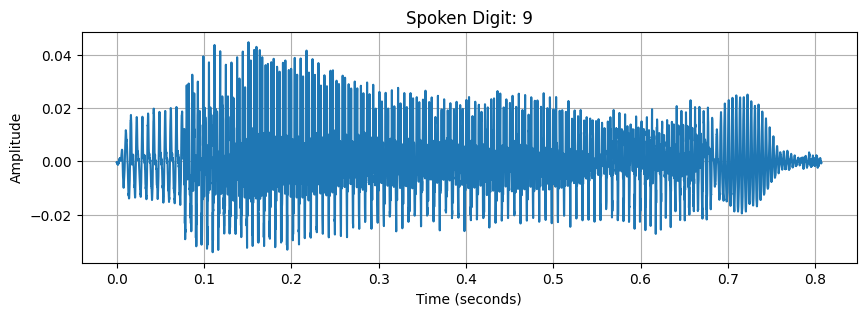

In [27]:
# Select a longer audio recording (at least 0.5 seconds)

example_item = None

for item in tfds.as_numpy(audio_ds):
    if len(item["audio"]) >= 4000:
        example_item = item
        break

example_waveform = np.asarray(
    example_item["audio"], dtype=np.float32
)

# Convert integer PCM values to normalized audio
example_waveform = example_waveform / 32768.0

label = int(example_item["label"])
digit = audio_info.features["label"].int2str(label)

duration = len(example_waveform) / SAMPLE_RATE

print("Spoken digit:", digit)
print("Duration:", round(duration, 2), "seconds")
print("Filename:", example_item["audio/filename"])

plt.figure(figsize=(10, 3))
plt.plot(
    np.arange(len(example_waveform)) / SAMPLE_RATE,
    example_waveform
)
plt.title(f"Spoken Digit: {digit}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

display(Audio(
    example_waveform,
    rate=SAMPLE_RATE,
    normalize=True
))

In [19]:
# STEP 18: BUILD THE AUDIO LSTM MODEL

def build_audio_lstm(input_shape, num_classes):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        tf.keras.layers.LSTM(64),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


audio_lstm_model = build_audio_lstm(
    input_shape=(MAX_FRAMES, N_MFCC),
    num_classes=NUM_CLASSES
)

audio_lstm_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 64)             │        19,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,378 (87.41 KB)

 Trainable params: 22,378 (87.41 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# STEP 19: BUILD THE BIDIRECTIONAL AUDIO LSTM MODEL

def build_audio_bilstm(input_shape, num_classes):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(32)
        ),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


audio_bilstm_model = build_audio_bilstm(
    input_shape=(MAX_FRAMES, N_MFCC),
    num_classes=NUM_CLASSES
)

audio_bilstm_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        11,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,186 (55.41 KB)

 Trainable params: 14,186 (55.41 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# STEP 20: TRAIN BOTH AUDIO MODELS

audio_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

AUDIO_EPOCHS = 15
AUDIO_BATCH_SIZE = 32

print("Training audio LSTM...")
audio_history_lstm = audio_lstm_model.fit(
    X_audio_train,
    y_audio_train,
    validation_data=(X_audio_val, y_audio_val),
    epochs=AUDIO_EPOCHS,
    batch_size=AUDIO_BATCH_SIZE,
    callbacks=[audio_early_stop],
    verbose=1
)

print("\nTraining audio Bidirectional LSTM...")
audio_history_bilstm = audio_bilstm_model.fit(
    X_audio_train,
    y_audio_train,
    validation_data=(X_audio_val, y_audio_val),
    epochs=AUDIO_EPOCHS,
    batch_size=AUDIO_BATCH_SIZE,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Training audio LSTM...
Epoch 1/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.1011 - loss: 2.3080 - val_accuracy: 0.1000 - val_loss: 2.3037
Epoch 2/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.0944 - loss: 2.3056 - val_accuracy: 0.1044 - val_loss: 2.3030
Epoch 3/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.0928 - loss: 2.3037 - val_accuracy: 0.1044 - val_loss: 2.3024
Epoch 4/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1111 - loss: 2.2809 - val_accuracy: 0.1667 - val_loss: 2.1482
Epoch 5/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1728 - loss: 2.1045 - val_accuracy: 0.1800 - val_loss: 2.0445
Epoch 6/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.1717 - loss: 1.9812 - val_accuracy: 0.1756 - val_loss: 2.0171
Epoch 7/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.1983 - loss: 1.8183 - val_accuracy: 0.2044 - val_loss: 1.7577
Epoch 8/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.2228 - loss: 1.7382 - v

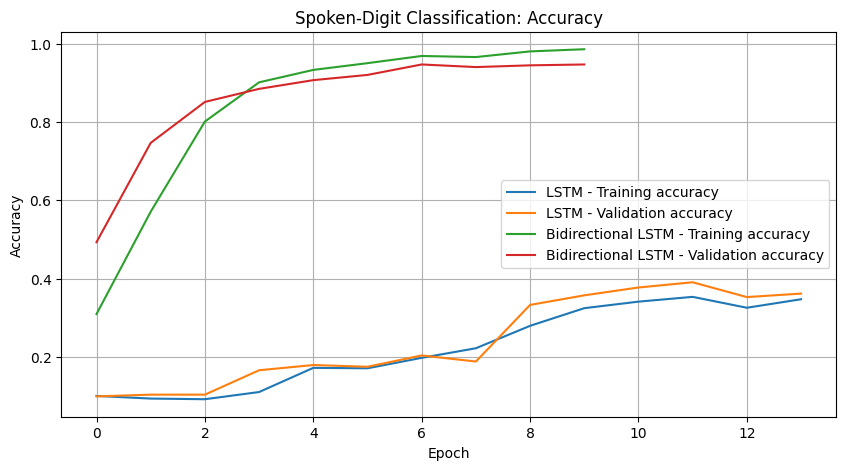

In [22]:
# STEP 21: PLOT AUDIO MODEL TRAINING ACCURACY

plt.figure(figsize=(10, 5))

plt.plot(
    audio_history_lstm.history["accuracy"],
    label="LSTM - Training accuracy"
)
plt.plot(
    audio_history_lstm.history["val_accuracy"],
    label="LSTM - Validation accuracy"
)
plt.plot(
    audio_history_bilstm.history["accuracy"],
    label="Bidirectional LSTM - Training accuracy"
)
plt.plot(
    audio_history_bilstm.history["val_accuracy"],
    label="Bidirectional LSTM - Validation accuracy"
)

plt.title("Spoken-Digit Classification: Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
# STEP 22: EVALUATE AUDIO CLASSIFICATION MODELS

audio_lstm_prob = audio_lstm_model.predict(X_audio_test, verbose=0)
audio_bilstm_prob = audio_bilstm_model.predict(X_audio_test, verbose=0)

audio_lstm_pred = np.argmax(audio_lstm_prob, axis=1)
audio_bilstm_pred = np.argmax(audio_bilstm_prob, axis=1)

audio_lstm_accuracy = accuracy_score(y_audio_test, audio_lstm_pred)
audio_bilstm_accuracy = accuracy_score(y_audio_test, audio_bilstm_pred)

audio_results = pd.DataFrame({
    "Model": ["LSTM", "Bidirectional LSTM"],
    "Test Accuracy": [audio_lstm_accuracy, audio_bilstm_accuracy]
})

display(audio_results)

print("LSTM classification report:")
print(classification_report(
    y_audio_test,
    audio_lstm_pred,
    labels=list(range(NUM_CLASSES)),
    zero_division=0
))

print("Bidirectional LSTM classification report:")
print(classification_report(
    y_audio_test,
    audio_bilstm_pred,
    labels=list(range(NUM_CLASSES)),
    zero_division=0
))

,Model,Test Accuracy
0,LSTM,0.400
1,Bidirectional LSTM,0.976


LSTM classification report:
              precision    recall  f1-score   support

           0       1.00      0.04      0.08        25
           1       0.62      0.20      0.30        25
           2       0.30      0.12      0.17        25
           3       0.00      0.00      0.00        25
           4       0.51      1.00      0.68        25
           5       0.53      0.72      0.61        25
           6       0.00      0.00      0.00        25
           7       0.50      0.12      0.19        25
           8       0.26      1.00      0.41        25
           9       0.43      0.80      0.56        25

    accuracy                           0.40       250
   macro avg       0.42      0.40      0.30       250
weighted avg       0.42      0.40      0.30       250

Bidirectional LSTM classification report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98        25
           1       1.00      1.00      1.00        25
        

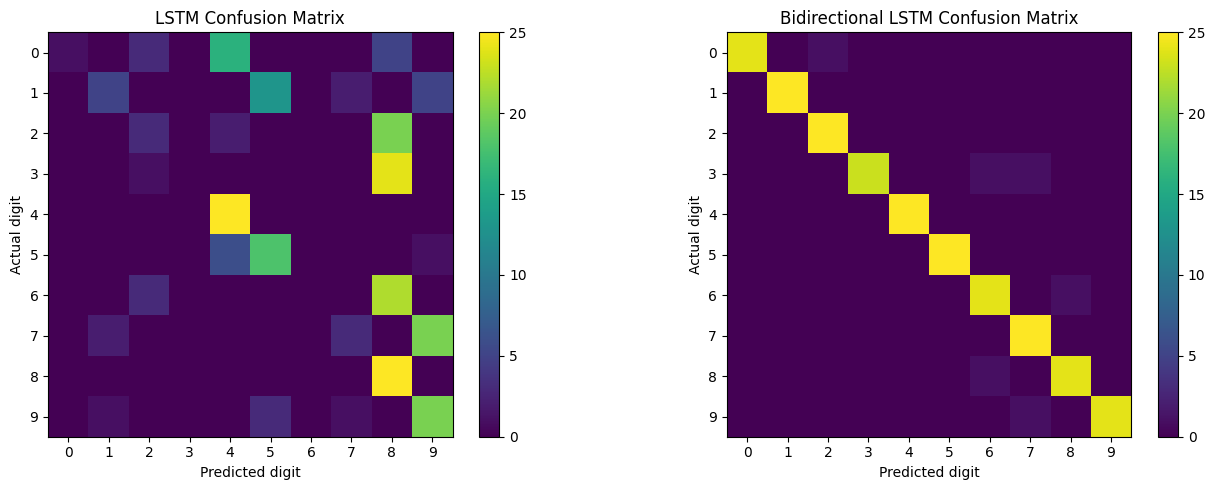

In [24]:
# STEP 23: CONFUSION MATRICES FOR AUDIO CLASSIFICATION

cm_lstm = confusion_matrix(
    y_audio_test, audio_lstm_pred,
    labels=list(range(NUM_CLASSES))
)

cm_bilstm = confusion_matrix(
    y_audio_test, audio_bilstm_pred,
    labels=list(range(NUM_CLASSES))
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, cm, title in [
    (axes[0], cm_lstm, "LSTM Confusion Matrix"),
    (axes[1], cm_bilstm, "Bidirectional LSTM Confusion Matrix")
]:
    image = ax.imshow(cm, interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel("Predicted digit")
    ax.set_ylabel("Actual digit")
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_yticks(range(NUM_CLASSES))
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

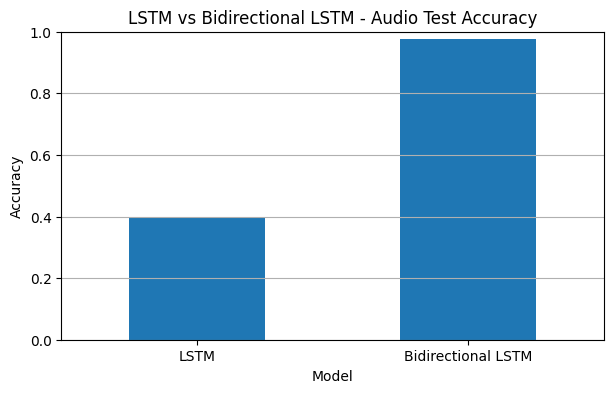

In [25]:
# STEP 24: COMPARE AUDIO TEST ACCURACY

audio_results.set_index("Model").plot(
    kind="bar",
    figsize=(7, 4),
    legend=False
)

plt.title("LSTM vs Bidirectional LSTM - Audio Test Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

## Final comparison and conclusion

The notebook evaluates two different sequence-learning tasks:

| Track | Input | Output | Evaluation |
|---|---|---|---|
| Structured | 24 hours of weather measurements | Temperature one hour ahead | MAE, RMSE |
| Unstructured | MFCC time sequence from a spoken audio waveform | Digit class (0–9) | Accuracy, confusion matrix |

**Expected learning outcome:** An LSTM uses a memory cell and gates to regulate information flow over time. A Bidirectional LSTM processes the sequence in forward and backward directions. In audio classification, both directions can use the full MFCC sequence as context. For forecasting, a Bidirectional LSTM is applied only to the historical input window; it does not receive future observations.

Do not assume the Bidirectional LSTM will always perform better. Record the actual metrics obtained in your Colab run.

### Conclusion

LSTM and Bidirectional LSTM networks were implemented for structured weather forecasting and unstructured audio classification. The weather experiment used MinMax scaling and sliding windows, while the audio experiment used Librosa to extract MFCC sequences from spoken-digit waveforms. Both models were trained and evaluated, and their performance was compared using appropriate metrics and visualizations.

## Optional: save the trained models

Run this cell after completing both tracks. The files will be saved in the Colab `/content` directory. Download them from the Files panel if needed.

In [26]:
lstm_model.save("/content/weather_lstm.keras")
bilstm_model.save("/content/weather_bilstm.keras")

audio_lstm_model.save("/content/audio_lstm.keras")
audio_bilstm_model.save("/content/audio_bilstm.keras")

print("All four models saved successfully.")

All four models saved successfully.
